In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import sqrt

df = pd.read_csv("Data/health_study_dataset.csv")
df_numeric = df[["age","height","weight","systolic_bp","cholesterol"]]

# Beskrivande analys

Medel, median, min, max

In [2]:
df_base_info = pd.DataFrame({
    'mean': df_numeric.mean(),
    'median': df_numeric.median(),
    'min': df_numeric.min(),
    'max': df_numeric.max()
})

df_base_info

,mean,median,min,max
age,49.426250,50.00,18.0,90.00
height,171.849250,171.35,144.4,200.40
weight,73.413000,73.20,33.7,114.40
systolic_bp,149.178625,149.40,106.8,185.90
cholesterol,4.929150,4.97,2.5,7.88


Grafer

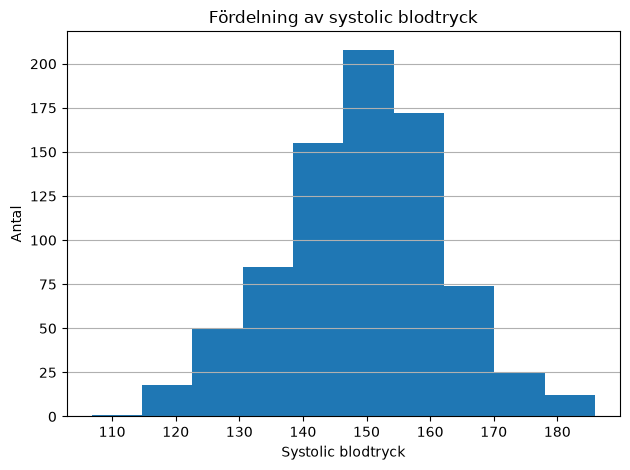

In [3]:
fig, ax = plt.subplots()
ax.hist(df["systolic_bp"].dropna(), bins=10)
ax.set_title("Fördelning av systolic blodtryck")
ax.set_xlabel("Systolic blodtryck")
ax.set_ylabel("Antal")
ax.grid(True, axis = "y")
plt.tight_layout()

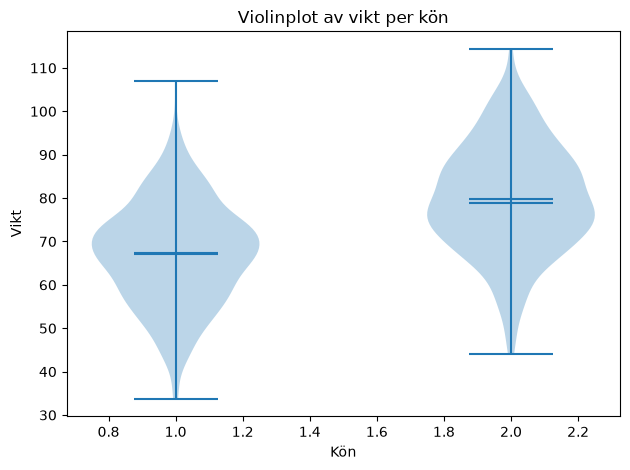

In [4]:
fig, ax = plt.subplots()
ax.violinplot([df.loc[df.sex == "F", "weight"], df.loc[df.sex == "M", "weight"]], showmeans=True, showmedians=True)
ax.set_title("Violinplot av vikt per kön")
ax.set_xlabel("Kön")
ax.set_ylabel("Vikt")
plt.tight_layout()

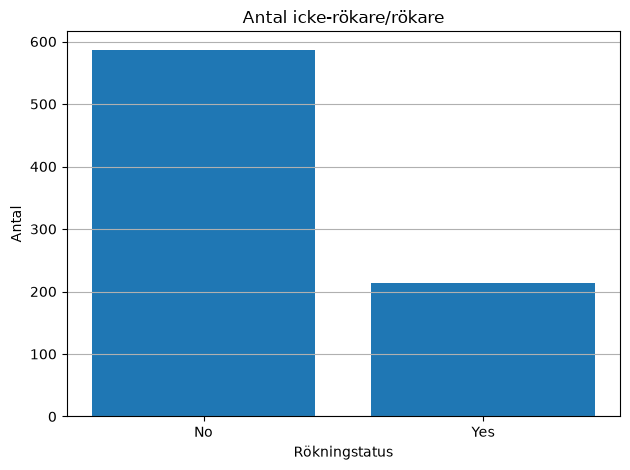

In [5]:
def count_of_smokers(df: pd.DataFrame) -> pd.DataFrame:

    return (
        df.groupby("smoker", dropna=False)["id"]
        .nunique()
        .sort_values(ascending=False)
        .reset_index(name="antal")
    )

fig, ax = plt.subplots()
ax.bar(count_of_smokers(df)["smoker"], count_of_smokers(df)["antal"])
ax.set_title("Antal icke-rökare/rökare")
ax.set_xlabel("Rökningstatus")
ax.set_ylabel("Antal")
ax.grid(True, axis = "y")
plt.tight_layout()

# Simulering kopplad till caset

In [6]:
np.random.seed(61)

Andelen personer i datasetet som har sjukdomen: 5.875%

In [7]:
andel_sjuk = sum(df["disease"]) / df["disease"].count() * 100

print(andel_sjuk)

5.875


Simulera 1000 slumpade personer med samma sannolikhet för sjukdom

In [8]:
n_sim = 1_000

true_p_sjuk = 0.05875

sjuk_sim = np.random.binomial(n=1, p=true_p_sjuk, size=n_sim)

df_sim = pd.DataFrame({
    "disease": sjuk_sim,
})

Jämför den simulerade andelen med den verkliga andelen i datasetet

- Den simulerade andelen blev 5,7%, 0,175% mindre än den riktiga andelen

In [9]:
andel_sjuk_sim = sum(df_sim["disease"]) / df_sim["disease"].count() * 100

print(andel_sjuk_sim)

5.3


# Konfidensintervall

Konfidensintervall för medelvärdet av systolic blodtryck

In [10]:
def ci_mean_normal(x, confidence=0.95):

    x = np.asarray(x, dtype=float)
    mean_x = float(np.mean(x))
    s = float(np.std(x, ddof=1))
    n = len(x)

    z_critical = 1.96
    half_width = z_critical * s / sqrt(n)
    lo, hi = mean_x - half_width, mean_x + half_width
    return lo, hi, mean_x, s, n

lo, hi, mean_x, s, n = ci_mean_normal(df["systolic_bp"])
(lo, hi)

(148.29209036025347, 150.06515963974655)

# Hypotesprövning

Hypotesen: rökare har högre medel-blodtryck än icke-rökare

- Vi använder Welch's t-test eftersom vi vet inte om varianserna är lika och gör det "one-sided" för att vår hypotes är att rökarnas medel-blodtryck är högre än icke-rökarnas
- Med ett p-värde på 0,326 ser vi inget statistiskt stöd till vår hypotes

In [11]:
no = df.loc[df.smoker == "No", "systolic_bp"].values
yes = df.loc[df.smoker == "Yes", "systolic_bp"].values

t_stat_w, p_val_w = stats.ttest_ind(no, yes, equal_var=False, alternative="less")

print(p_val_w)


0.32636693716994986
